# Laboratório 4: MC Básico

## Importações

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import ListedColormap
import seaborn as sns
from typing import Dict, Tuple, List, Union, Optional, Set
from numpy import linalg as LA
from collections import defaultdict
from tqdm.auto import tqdm

/home/alomy/.pyenv/versions/3.14.4/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Ambiente: Navegação no Labirinto (gridworld)

In [2]:
# Ambiente: Navegação no Labirinto (gridworld)
class AmbienteNavegacaoLabirinto:
    """
    Navegação no Labirinto (gridworld) determinístico para experimentos de aprendizado por reforço.

    Política de recompensa:
    - A recompensa é calculada com base na tentativa de movimento (s, a -> posição proposta), antes de aplicar rebote por sair da grade ou por entrada proibida em bad_states.
    - Se a tentativa mira fora da grade: r_boundary
    - Se mira um bad_state: r_bad
    - Se mira um target_state: r_target
    - Caso contrário: r_other

    Terminação:
    - Por padrão, o ambiente não encerra episódios automaticamente (target_states/bad_states não são estados terminais).
    """

    def __init__(
        self,
        world_size: Tuple[int, int],
        bad_states: List[Tuple[int, int]],
        target_states: List[Tuple[int, int]],
        allow_bad_entry: bool = False,
        rewards: Optional[List[float]] = None
    ) -> None:
        """
        Inicializa o ambiente de navegação em labirinto.

        Parâmetros
        ----------
        world_size : (n_linhas, n_colunas)
            Dimensões da grade.
        bad_states : lista de (linha, coluna)
            Coordenadas dos estados com penalidade.
        target_states : lista de (linha, coluna)
            Coordenadas dos estados-alvo.
        allow_bad_entry : bool
            Se False, impede entrada em bad_states (rebote para o estado atual).
        rewards : [r_boundary, r_bad, r_target, r_other]
            Recompensas possíveis. Se None, usa [-1, -1, 1, 0].
        """
        if rewards is None:
            rewards = [-1, -1, 1, 0]

        self.n_rows, self.n_cols = world_size   # dimensões da grade do labirinto
        self.bad_states = set(bad_states)       # estados com penalidade alta
        self.target_states = set(target_states) # estados com recompensa alta
        self.allow_bad_entry = allow_bad_entry  # se o agente pode entrar em estados ruins

        # Validações
        for st in self.bad_states | self.target_states:
            if not (0 <= st[0] < self.n_rows and 0 <= st[1] < self.n_cols):
                raise ValueError(f"Estado {st} fora dos limites.")
        if self.bad_states & self.target_states:
            raise ValueError("bad_states e target_states devem ser disjuntos.")

        # Recompensas definidas para cada tipo de transição
        self.r_boundary = rewards[0]    # tentar sair da grade
        self.r_bad      = rewards[1]    # transição para estado ruim
        self.r_target   = rewards[2]    # transição para estado alvo
        self.r_other    = rewards[3]    # demais transições

        # Espaço de ações: dicionário com deslocamentos (linha, coluna)
        self.action_space = {
            0: (-1, 0),  # cima
            1: (1, 0),   # baixo
            2: (0, -1),  # esquerda
            3: (0, 1),   # direita
            4: (0, 0)    # permanecer no mesmo estado
        }

        # Espaço de recompensas: lista de recompensas possíveis
        self.recompensas_possiveis = np.array(sorted(set(rewards)))
        self.reward_map = {r: i for i, r in enumerate(self.recompensas_possiveis)}

        # número total de estados
        self.n_states = self.n_rows * self.n_cols

        # número total de ações
        self.n_actions = len(self.action_space)

        # número total de recompensas possíveis
        self.n_rewards = self.recompensas_possiveis.shape[0]

        # Tensor de probabilidades de transição: P(s'|s,a)
        self.state_transition_probabilities = np.zeros((self.n_states, self.n_states, self.n_actions))

        # Tensor de probabilidade de recompensas: P(r|s,a)
        self.reward_probabilities = np.zeros((self.n_rewards, self.n_states, self.n_actions))

        # Matriz de recompensa imediata (determinística): recompensa[s, a] = r
        self.recompensas_imediatas = np.zeros((self.n_states, self.n_actions))

        # Matriz de transição de estados (determinística): transicao[s, a] = s'
        self.transicao_de_estados = np.zeros((self.n_states, self.n_actions), dtype=int)

        self.agent_pos = (0, 0)  # posição inicial do agente

        self._init_dynamics()  # inicializa as dinâmicas de transição e recompensa


    def __repr__(self) -> str:
        return (f"AmbienteNavegacaoLabirinto({self.n_rows}x{self.n_cols}, "
                f"bad={len(self.bad_states)}, target={len(self.target_states)}, "
                f"allow_bad_entry={self.allow_bad_entry}, agent_pos={self.agent_pos})")


    def __str__(self) -> str:
        return self.render(as_string=True)


    def reset(self) -> Tuple[int, int]:
        """
        Reinicia a posição do agente para o estado inicial (0, 0).

        Retorna
        -------
        (linha, coluna) : posição inicial do agente.
        """
        self.agent_pos = (0, 0)
        return self.agent_pos


    def step(self, acao: int, *, linear: bool = False) -> Tuple[Union[int, Tuple[int, int]], float]:
        """
        Executa uma ação, atualiza a posição do agente e devolve o próximo estado.

        Parâmetros
        ----------
        acao : int
            Índice da ação (0-4).
        linear : bool, keyword-only (default=False)
            Se True, retorna o estado como índice linear {0,...,self.n_states-1}; caso contrário, retorna tupla (linha, coluna).

        Retorna
        -------
        proximo_estado : int | (int, int)
            Estado observado após a transição (com possível rebote).
        recompensa : float
            Recompensa imediata recebida.
        """
        estado_atual = self.agent_pos                                           # armazena o estado atual do agente
        proposta = self._proposta(estado_atual, acao)                           # calcula a posição proposta pela ação
        recompensa = self._compute_reward(proposta)                             # avalia a recompensa com base na tentativa
        destino = self._destino_final(estado_atual, acao)                       # aplica regras e obtém o destino após possíveis rebotes
        self.agent_pos = destino                                                # atualiza a posição interna do agente
        proximo_estado = self.state_to_index(destino) if linear else destino    # escolhe o formato da observação de saída
        return proximo_estado, recompensa                                       # retorna observação e recompensa


    def reset_to_state(self, estado: Union[Tuple[int, int], int], verificar_validade_estado: bool = True) -> Tuple[int, int]:
        """
        Teleporta o agente para `estado` sem reiniciar o episódio completo.

        Parâmetros
        ----------
        estado : (linha, coluna) | int
            Tupla de coordenadas (linha, coluna) ou índice linear (int).
        verificar_validade_estado : bool
            Se True, lança ValueError se o estado for inválido.

        Retorna
        -------
        (linha, coluna) : nova posição do agente.
        """
        # Converte índice -> tupla, se necessário
        if isinstance(estado, int):
            estado = self.index_to_state(estado)

        if verificar_validade_estado and not self._in_bounds(estado):
            raise ValueError(f"Estado {estado} fora dos limites do labirinto.")

        self.agent_pos = tuple(estado)      # mantém tupla imutável

        return self.agent_pos


    def is_bad(self, state: Union[int, Tuple[int, int]]) -> bool:
        """Retorna True se o estado for um bad_state."""
        if isinstance(state, int):
            state = self.index_to_state(state)
        return state in self.bad_states


    def is_target(self, state: Union[int, Tuple[int, int]]) -> bool:
        """Retorna True se o estado for um target_state."""
        if isinstance(state, int):
            state = self.index_to_state(state)
        return state in self.target_states


    def state_to_index(self, estado: Tuple[int, int]) -> int:
        """
        Converte coordenada (linha, coluna) para índice linear no intervalo [0, n_states-1].
        """
        linha, coluna = estado
        return linha * self.n_cols + coluna


    def index_to_state(self, indice: int) -> Tuple[int, int]:
        """
        Converte índice linear  no intervalo [0, n_states-1] para coordenada (linha, coluna).
        """
        return divmod(indice, self.n_cols)  # (linha, coluna) = (indice // self.n_cols, indice % self.n_cols)


    def enumerate_states(self) -> List[int]:
        """Retorna a lista de índices lineares de todos os estados [0, ..., n_states - 1]."""
        return list(range(self.n_states))


    def enumerate_actions(self) -> List[int]:
        """Retorna a lista de índices das ações disponíveis [0, ..., n_actions - 1]."""
        return list(self.action_space.keys())


    def render(
        self,
        *,
        as_string: bool = True,
        show_coords: bool = False,
        legend: bool = True,
        chars: dict | None = None
    ) -> str:
        """
        Renderização ASCII do grid.
        - A: agente, B: bad, T: target, .: vazio
        - show_coords: mostra índices de linha/coluna
        - legend: inclui legenda ao final
        - chars: permite customizar símbolos (keys: 'agent','bad','target','empty')
        """
        if chars is None:
            chars = {"agent": "A", "bad": "B", "target": "T", "empty": "."}

        linhas = []

        # cabeçalho de colunas
        if show_coords:
            header = "    " + " ".join(f"{c:2d}" for c in range(self.n_cols))
            linhas.append(header)
            linhas.append("    " + "--" * self.n_cols)

        # monta o grid linha a linha
        for r in range(self.n_rows):
            row_syms = []
            for c in range(self.n_cols):
                sym = chars["empty"]
                if (r, c) in self.bad_states:
                    sym = chars["bad"]
                if (r, c) in self.target_states:
                    sym = chars["target"]
                if self.agent_pos == (r, c):
                    sym = chars["agent"]
                row_syms.append(sym)

            linha_str = " ".join(row_syms)
            if show_coords:
                linhas.append(f"{r:2d} | {linha_str}")
            else:
                linhas.append(linha_str)

        # legenda
        if legend:
            linhas.append("")
            linhas.append(f"Legenda: {chars['agent']}=agente, {chars['bad']}=bad, "
                        f"{chars['target']}=target, {chars['empty']}=vazio")

        out = "\n".join(linhas)
        return out if as_string else print(out)


    def plot_labirinto(self, ax=None, titulo: str = "Visualização do Labirinto", cbar: bool = False):
        """
        Visualiza o labirinto.

        Representa:
        - Estado neutro: branco
        - Estado ruim: vermelho
        - Estado alvo: verde

        Parâmetros
        ----------
        ax : matplotlib.axes.Axes, opcional
            Eixo onde desenhar. Se None, cria uma nova figura.
        titulo : str, opcional
            Título do gráfico.
        cbar : bool, opcional (default=False)
            Exibe (True) ou oculta (False) a barra de cores.

        Retorna
        -------
        ax : matplotlib.axes.Axes
            Eixo com o heatmap.
        """
        # Cria matriz com valores padrão (0 = neutro)
        matriz = np.zeros((self.n_rows, self.n_cols), dtype=int)

        # marca estados
        for (r, c) in self.bad_states:
            matriz[r, c] = 1   # ruim
        for (r, c) in self.target_states:
            matriz[r, c] = 2   # alvo

        # cores: branco=neutro, vermelho=ruim, verde=alvo
        cmap = ListedColormap(["white", "red", "green"])

        fig = None
        if ax is None:
            fig, ax = plt.subplots(figsize=(self.n_cols, self.n_rows))

        ax = sns.heatmap(
            matriz,
            cmap=cmap,
            cbar=cbar,
            linewidths=0.5,
            linecolor="gray",
            square=True,
            ax=ax
        )

        # remove ticks/labels
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_xticklabels([]); ax.set_yticklabels([])

        # bordas externas
        for side in ("left", "right", "top", "bottom"):
            ax.spines[side].set_visible(True)
            ax.spines[side].set_linewidth(0.5)
            ax.spines[side].set_edgecolor("gray")

        ax.set_title(titulo)

        if fig is not None:
            plt.tight_layout()
            plt.show()

        return


    def _init_dynamics(self):
        """
        Preenche as matrizes de transição e recompensa com base na estrutura do ambiente e regras de movimentação.
        """

        self.recompensas_imediatas.fill(0.0)
        self.transicao_de_estados.fill(0)
        self.state_transition_probabilities.fill(0.0)
        self.reward_probabilities.fill(0.0)

        for s in self.enumerate_states():                                   # percorre todos os estados (índices lineares)
            estado_atual = self.index_to_state(s)                           # converte índice para (linha, coluna)
            for a in self.enumerate_actions():                              # percorre todas as ações disponíveis
                proposta = self._proposta(estado_atual, a)                  # calcula a posição proposta pela ação
                r = self._compute_reward(proposta)                          # avalia a recompensa da tentativa de movimento
                destino = self._destino_final(estado_atual, a)              # obtém destino após aplicar regras de rebote
                s_next = self.state_to_index(destino)                       # converte destino para índice linear

                self.recompensas_imediatas[s, a] = r                        # registra r(s, a) na matriz de recompensas imediatas
                self.transicao_de_estados[s, a] = s_next                    # registra T(s, a) = s' na matriz de transições

                self.state_transition_probabilities[s_next, s, a] = 1.0     # define P(s'|s, a) = 1 (ambiente determinístico)
                self.reward_probabilities[self.reward_map[r], s, a] = 1.0   # define P(r |s, a) = 1 (ambiente determinístico)


    def _proposta(self, state: Tuple[int, int], acao: int) -> Tuple[int, int]:
        """Retorna a posição proposta (antes de qualquer rebote)."""
        dl, dc = self.action_space[acao]
        return (state[0] + dl, state[1] + dc)


    def _destino_final(self, state: Tuple[int, int], acao: int) -> Tuple[int, int]:
        """
        Aplica as regras de rebote: fora da grade => rebote;
        bad_state com allow_bad_entry=False => rebote; caso contrário segue para a proposta.
        """
        proposta = self._proposta(state, acao)
        if not self._in_bounds(proposta):
            return state
        if (not self.allow_bad_entry) and self.is_bad(proposta):
            return state
        return proposta


    def _in_bounds(self, posicao: Tuple[int, int]) -> bool:
        """
        Verifica se uma posição está dentro dos limites do labirinto.

        Parâmetros
        ----------
        posicao : (linha, coluna)

        Retorna
        -------
        bool : True se dentro da grade, False caso contrário.
        """
        linha, coluna = posicao
        return 0 <= linha < self.n_rows and 0 <= coluna < self.n_cols


    def _compute_reward(self, destino: Tuple[int, int]) -> float:
        """
        Calcula a recompensa da tentativa de transição para 'destino'.

        Regras
        ------
        - Se 'destino' está fora da grade: r_boundary
        - Se 'destino' é bad_state: r_bad
        - Se 'destino' é target_state: r_target
        - Caso contrário: r_other
        """
        if not self._in_bounds(destino):
            return self.r_boundary
        elif self.is_bad(destino):
            return self.r_bad
        elif self.is_target(destino):
            return self.r_target
        else:
            return self.r_other

## Funções auxiliares para visualização

In [3]:
def _prepare_grid(env, ax=None, draw_cells=True):
    """
    Configura o grid. Se 'ax' não for passado, cria 'fig, ax'; caso contrário retorna 'fig=None, ax'.
    """
    fig = None
    if ax is None:
        fig, ax = plt.subplots(figsize=(env.n_cols, env.n_rows))

    ax.set_xlim(0, env.n_cols)
    ax.set_ylim(0, env.n_rows)
    ax.set_xticks(np.arange(0, env.n_cols + 1, 1))
    ax.set_yticks(np.arange(0, env.n_rows + 1, 1))
    ax.grid(True)
    ax.set_aspect('equal')
    ax.invert_yaxis()

    if draw_cells:
        for r in range(env.n_rows):
            for c in range(env.n_cols):
                cell = (r, c)
                if cell in env.bad_states:
                    color = 'red'
                elif cell in env.target_states:
                    color = 'green'
                else:
                    color = 'white'
                rect = patches.Rectangle((c, r), 1, 1, facecolor=color, edgecolor='gray')
                ax.add_patch(rect)

    return fig, ax

def _coerce_policy(env, policy):
    """
    Normaliza a política para o formato dict[(r,c)] -> ação (int).
    Aceita:
      - dict[(r,c)] -> ação
      - dict[(r,c)] -> vetor de probabilidades
      - Pi ndarray (n_estados, n_acoes)
    """
    # caso 1: matriz Pi (ndarray)
    if isinstance(policy, np.ndarray):
        a_star = np.argmax(policy, axis=1)
        return {env.index_to_state(s): int(a_star[s]) for s in range(env.n_states)}

    # caso 2: dicionário
    sample_val = next(iter(policy.values()))
    if isinstance(sample_val, np.ndarray):
        return {pos: int(np.argmax(probs)) for pos, probs in policy.items()}
    else:
        return policy

def plot_policy(env, policy, ax=None, titulo="Política"):
    """
    Desenha setas/círculos de uma política. 'policy' pode ser:
      - dict[(r,c)] -> ação
      - dict[(r,c)] -> vetor de probabilidades
      - ndarray com shape (n_estados, n_acoes)
    """
    fig, ax = _prepare_grid(env, ax=ax)

    policy_dict = _coerce_policy(env, policy)
    color = 'black'
    lw = 1.5

    for (r, c), action in policy_dict.items():
        x, y = c + 0.5, r + 0.5
        if action == 0:      # cima
            ax.arrow(x, y, dx=0, dy=-0.3, head_width=0.2, head_length=0.2, fc=color, ec=color, linewidth=lw)
        elif action == 1:    # baixo
            ax.arrow(x, y, dx=0, dy=0.3, head_width=0.2, head_length=0.2, fc=color, ec=color, linewidth=lw)
        elif action == 2:    # esquerda
            ax.arrow(x, y, dx=-0.3, dy=0, head_width=0.2, head_length=0.2, fc=color, ec=color, linewidth=lw)
        elif action == 3:    # direita
            ax.arrow(x, y, dx=0.3, dy=0, head_width=0.2, head_length=0.2, fc=color, ec=color, linewidth=lw)
        elif action == 4:    # ficar
            circ = patches.Circle((x, y), 0.1, edgecolor=color, facecolor='none', linewidth=lw)
            ax.add_patch(circ)

    ax.set_title(titulo)
    if fig is not None:
        plt.tight_layout()
        plt.show()
    return ax

def plot_tabular(
    data,
    kind: str = "Q",          # "Q" (valores de ação), "Pi" (política), "V" (valores de estado)
    ambiente=None,            # necessário quando kind="V" para reshape
    ax=None,
    cbar: bool = True,
    fmt: str = ".1f",
    center_zero: bool = True  # só relevante para "Q" e "V"
):
    """
    Plota matrizes tabulares de RL em formato de heatmaps (mapas de calor).
    Esta função cobre 3 casos:
    1. kind="Q": heatmap de Q(s, a) com ações nas linhas e estados nas colunas.
    2. kind="Pi": heatmap de Pi(a|s) (probabilidades) com ações nas linhas e estados nas colunas.
    3. kind="V": heatmap de V(s) no grid (n_rows x n_cols) do ambiente .

    Parameters
    ----------
    data : ndarray
        Dados a serem plotados.
        - Para kind="Q" ou "Pi": array 2D com shape (n_estados, n_acoes).
        - Para kind="V": array 1D com shape (n_estados,) que será remodelado para (ambiente.n_rows, ambiente.n_cols).
    kind : {"Q", "Pi", "V"}, default="Q"
        Tipo do plot:
        - "Q" usa paleta divergente centrada em zero.
        - "Pi" usa paleta sequencial no intervalo [0, 1].
        - "V" plota o valor de estado no grid do ambiente.
    ambiente : object, optional
        Necessário quando kind="V". Deve expor n_rows e n_cols para o reshape.
    ax : matplotlib.axes.Axes, optional
        Eixo onde o heatmap será desenhado. Se None, uma nova figura/eixo é criado.
    cbar : bool, default=True
        Se True, exibe a barra de cores (colorbar).
    fmt : str, default=".1f"
        Formatação dos valores anotados em cada célula do heatmap.
    center_zero : bool, default=True
        Quando kind é "Q" ou "V", centraliza a escala de cores em zero (vmin=-absmax, vmax=absmax). Ignorado para "Pi".

    Returns
    -------
    ax : matplotlib.axes.Axes
        Eixo contendo o heatmap resultante.
    """
    kind = kind.upper()

    xlabel = {"V": "Colunas", "PI": "Estados", "Q": "Estados"}
    ylabel = {"V": "Linhas", "PI": "Ações", "Q": "Ações" }
    title  = {"V": "Valores de Estado (V(s))", "PI": r"Política ($\pi(a|s)$ transposta)", "Q": "Valores de ação (Q(s, a) transposta)"}

    fig = None

    #  V(s): precisa do shape do grid
    match kind:
        case "V":

            if ambiente is None:
                raise ValueError("Para kind='V', passe 'ambiente' para reshape (n_rows, n_cols).")

            M = data.reshape(ambiente.n_rows, ambiente.n_cols)

            if ax is None:
                fig, ax = plt.subplots(figsize=(ambiente.n_cols, ambiente.n_rows))

            if center_zero:
                vmax = float(np.abs(M).max())
                vmin = -vmax
            else:
                vmin = float(M.min())
                vmax = float(M.max())

            cmap, square = "bwr", True

        case "PI" | "Q":

            # Q(s,a) e Pi(a|s): ações nas linhas, estados nas colunas
            M = data.T  # data: (n_estados, n_acoes) -> transposto para (n_acoes, n_estados)
            n_acoes, n_estados = M.shape

            if ax is None:
                fig, ax = plt.subplots(figsize=(n_estados, n_acoes))

            if kind == "PI":
                cmap = "Blues";
                vmin, vmax = 0.0, 1.0
            else:  # "Q"
                cmap = "bwr"
                if center_zero:
                    vmax = float(np.abs(M).max())
                    vmin = -vmax
                else:
                    vmin = float(M.min())
                    vmax = float(M.max())

            square = False

        case _:
            raise ValueError(f"kind desconhecido: {kind!r} (use 'Q', 'Pi' ou 'V').")


    ax = sns.heatmap(
        data=M,
        annot=True,
        fmt=fmt,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        cbar=cbar,
        square=square,
        linewidths=0.5,
        linecolor="gray",
        ax=ax
    )

    ax.set_xlabel(xlabel[kind])
    ax.set_ylabel(ylabel[kind])
    ax.set_title(title[kind])

    # bordas externas
    for side in ("left", "right", "top", "bottom"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.5)
        ax.spines[side].set_edgecolor("gray")

    # rótulos
    if kind in ("Q", "PI"):
        ax.set_xticks(np.arange(n_estados) + 0.5)
        ax.set_xticklabels([f"s{i}" for i in range(n_estados)], rotation=0)
        ax.set_yticks(np.arange(n_acoes) + 0.5)
        ax.set_yticklabels([f"a{i}" for i in range(n_acoes)], rotation=0)

    if fig is not None:
        plt.tight_layout()
        plt.show()

    return

## Ambiente: nova instância

A instanciação do ambiente exige cinco parâmetros:

- `world_size=(n_linhas, n_colunas)`: dimensões da grade.
- `bad_states` e `target_states`: listas de coordenadas `(linha, coluna)`, com origem no canto superior esquerdo e índices começando em zero. Os dois conjuntos devem ser disjuntos.
- `allow_bad_entry`: se `True`, o agente pode entrar em estados ruins (paga a penalidade e segue); se `False`, o movimento é bloqueado e ele permanece onde está.
- `rewards=[r_boundary, r_bad, r_target, r_other]`: **a ordem importa**. Tentar sair da grade, entrar em estado ruim, entrar no alvo e qualquer outra transição, nessa sequência.

O ambiente é determinístico, tem cinco ações (cima, baixo, esquerda, direita, permanecer) e não possui estados terminais: o agente continua se movendo indefinidamente, inclusive após alcançar o alvo.

O labirinto é o mesmo dos Laboratórios 1 e 2, mas a forma de usá-lo muda. Até aqui, os algoritmos consultavam o modelo do ambiente diretamente: os tensores `Ps`, `Pr`, `R` e `T` no labirinto e o dicionário `env.P` no FrozenLake. Neste laboratório o modelo **não** é usado. Toda a informação vem da interação com o ambiente, por meio de dois métodos:

- `reset_to_state(estado)`: posiciona o agente em `estado`, dado como tupla `(linha, coluna)` ou como índice linear.
- `step(acao, linear=True)`: executa `acao` a partir da posição atual e devolve o par `(proximo_estado, recompensa)`. Com `linear=True` o próximo estado vem como índice linear; sem esse argumento, vem como tupla.

O índice linear numera as células linha a linha, da esquerda para a direita, e vale `linha * n_cols + coluna`; o estado `(2, 2)`, por exemplo, tem índice `12`. As matrizes `Q` e `Pi` usam esse mesmo índice: ambas têm shape `(n_estados, n_acoes)`, e a linha `12` de `Q` guarda os valores das cinco ações no estado `(2, 2)`, enquanto a linha `12` de `Pi` guarda as probabilidades dessas ações. É por isso que o próximo estado devolvido por `step` precisa vir como índice, e não como tupla.

Depois de criar a instância, você pode inspecionar a interação:

    ambiente.reset_to_state(12)            # estado (2, 2)
    print(ambiente.step(1, linear=True))   # ação 1 (baixo): (próximo estado, recompensa)

A célula abaixo cria a instância do baseline e exibe o labirinto, com branco para estados neutros, vermelho para ruins e verde para o alvo.

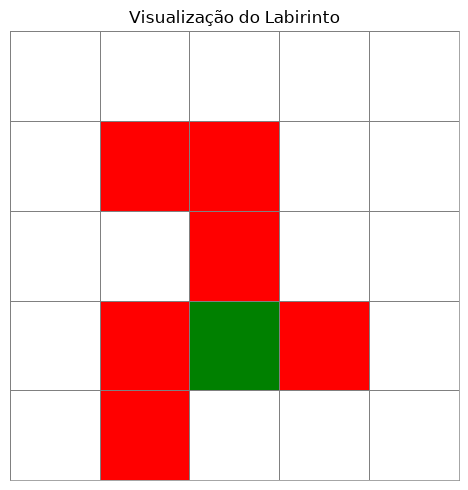

In [4]:
ambiente = AmbienteNavegacaoLabirinto(
        world_size=(5, 5),
        bad_states=[(1, 1), (1, 2), (2, 2), (3, 1), (3, 3), (4, 1)],
        target_states=[(3, 2)],
        allow_bad_entry=True,
        rewards=[-1, -10, 1, 0]
    )
ambiente.plot_labirinto()

## MC Básico

Nos laboratórios anteriores, a avaliação de uma política dependia do modelo do ambiente: calcular $Q(s,a)$ exigia conhecer as probabilidades de transição e as recompensas de cada par $(s,a)$. O MC básico mantém a estrutura da iteração de política do Laboratório 2, alternando avaliação e melhoria, mas substitui esse cálculo por uma estimativa construída a partir de experiência.

A ideia parte da definição do valor de ação como retorno esperado:

$$q_\pi(s,a) = \mathbb{E}\big[\,G_t \mid S_t = s,\ A_t = a\,\big]$$

Em vez de calcular essa esperança com o modelo, o MC básico gera episódios que começam em $s$ com a ação $a$ e seguem $\pi$ a partir daí, e usa a média dos retornos obtidos como aproximação de $q_\pi(s,a)$.

A implementação está dividida em quatro funções:
1. `gerar_episodio` (simula um episódio e devolve seu retorno)
2. `avaliar_politica_mc` (estima $Q$ para todos os pares)
3. `melhorar_politica` (o passo guloso)
4. `mc_basico` (o laço externo, já fornecido).

Implemente as três primeiras, preenchendo os blocos marcados.

### Episódio Monte-Carlo com horizonte fixo T

Implemente `gerar_episodio`, preenchendo o bloco marcado.

A função simula um episódio de exatamente `T` passos a partir de `estado_inicial` e devolve o retorno descontado

$$G = \sum_{t=0}^{T-1} \gamma^{t}\, r_{t+1} = r_1 + \gamma\, r_2 + \gamma^2\, r_3 + \cdots + \gamma^{T-1}\, r_T$$

em que $r_{t+1}$ é a recompensa recebida ao executar a ação do passo $t$. Note que:

- No primeiro passo, a ação é a **forçada**, `acao_inicial`;
- Do segundo em diante, é a ação que a **política** `Pi` escolhe no estado em que o agente se encontra.

A ação forçada é o que permite avaliar todos os pares $(s,a)$, inclusive aqueles cuja ação a política atual nunca escolheria.

Como o labirinto não tem estados terminais, o episódio nunca termina por conta própria: ele é interrompido após `T` passos. Note que `T`, aqui, é o comprimento do episódio, sem relação com a matriz de transição `T` dos Laboratórios 1 e 2.

A função não tem acesso ao modelo. A interação usa os dois métodos descritos na seção do ambiente: `reset_to_state` posiciona o agente em `estado_inicial`, e cada chamada a `step(acao, linear=True)` devolve o próximo estado e a recompensa. `Pi` tem shape `(n_estados, n_acoes)` e, por ser determinística, cada linha tem valor 1 na ação escolhida e 0 nas demais.

**Atenção:**
- O passo com a ação forçada **conta** entre os `T` passos, e sua recompensa tem peso $\gamma^0 = 1$: com `T = 2`, por exemplo, o retorno é $r_1 + \gamma\, r_2$, em que $r_1$ vem da ação forçada.
- Sem `linear=True`, `step` devolve o próximo estado como tupla `(linha, coluna)`, que não serve para indexar `Pi`.
- `reset_to_state` só reconhece índices do tipo `int` do Python.

A função deve retornar `G`, um número real.

In [5]:
def gerar_episodio(
    ambiente,
    estado_inicial: int,
    acao_inicial: int,
    Pi: np.ndarray,
    T: int,
    gamma: float,
) -> float:
    """
    Executa um episódio Monte Carlo de comprimento fixo T. O primeiro passo usa a ação forçada "acao_inicial", os demais seguem a política fornecida (Pi).

    Parâmetros
    ----------
    ambiente : AmbienteNavegacaoLabirinto
    estado_inicial : int
        Índice linear do estado inicial.
    acao_inicial : int
        Ação forçada no primeiro passo -> necessária para cobrir todo par (s,a).
    Pi : np.ndarray, shape (n_estados, n_acoes)
        Política seguida a partir do segundo passo.
    T : int
        Comprimento fixo do episódio.
    gamma : float
        Fator de desconto.

    Retorna
    -------
    G : float
        Retorno acumulado.
    """
    estado_atual = ambiente.reset_to_state(estado_inicial)
    proximo_estado, recompensa = ambiente.step(acao_inicial, linear=True)
    recompensas = [recompensa]
    estado_atual = proximo_estado

    for t in range(T - 1):
      probabilidade = Pi[estado_atual]
      acao = np.random.choice(len(probabilidade), p=probabilidade)
      proximo_estado, recompensa = ambiente.step(acao, linear=True)
      recompensas.append(recompensa)
      estado_atual = proximo_estado

    G = 0.0
    for r in reversed(recompensas):
      G =  r + gamma * G

    return G

### Avaliação Monte Carlo de uma política

Implemente `avaliar_politica_mc`, preenchendo o bloco marcado.

Para cada par $(s,a)$, a função gera `N` episódios com `gerar_episodio`, todos começando em $s$ com a ação forçada $a$, e estima o valor da ação pela média dos retornos:

$$Q(s,a) = \frac{1}{N} \sum_{i=1}^{N} g^{(i)}(s,a)$$

em que $g^{(i)}(s,a)$ é o retorno do $i$-ésimo episódio gerado para o par.

O acumulador `retornos` e a matriz `Q` já estão inicializados com zeros, ambos com shape `(n_estados, n_acoes)`. Os estados são os índices lineares de `0` a `n_estados - 1`, e as ações vão de `0` a `n_acoes - 1`.

**Atenção**:
- Todos os pares precisam ser avaliados, incluindo os estados ruins e o alvo, que aqui não são terminais, e as ações que a política atual não escolhe.

A função deve retornar `Q` com shape `(n_estados, n_acoes)`.

In [ ]:
def avaliar_politica_mc(
    ambiente,
    Pi: np.ndarray,
    gamma: float,
    T: int,
    N: int,
) -> np.ndarray:
    """
    Estima Q(s,a) por Monte Carlo com episódios de comprimento fixo T.
    Para cada par (s,a), gera N episódios e faz a média dos retornos.

    Parâmetros
    ----------
    ambiente : AmbienteNavegacaoLabirinto
        Instância do gridworld.
    Pi : np.ndarray, shape (n_estados, n_acoes)
        Política a ser avaliada.
    gamma : float
        Fator de desconto.
    T : int
        Horizonte fixo (número de passos por episódio).
    N : int
        Número de episódios gerados para cada par (s,a).
    """

    # Atalhos do ambiente (shapes)
    n_estados     = ambiente.n_states
    n_acoes       = ambiente.n_actions

    # Inicializações
    Q           = np.zeros((n_estados, n_acoes), dtype=float)   # armazena as médias
    retornos    = np.zeros((n_estados, n_acoes), dtype=float)   # acumula os retornos

    for s in range(n_estados):
        for a in range(n_acoes):
            for _ in range(N):
                retornos[s, a] += gerar_episodio(ambiente, s, a, Pi, T, gamma)
            Q[s, a] = retornos[s, a] / N

    return Q

### Melhoria de política

Implemente `melhorar_politica`, preenchendo o bloco marcado.

O passo guloso é o mesmo dos laboratórios anteriores. A diferença está na entrada: a função recebe `Q` já estimado e, por isso, não consulta o modelo. Em cada estado, a nova política escolhe a ação de maior valor:

$$a^*(s) = \arg\max_{a} Q(s,a)$$

A política resultante atribui probabilidade 1 à ação $a^*(s)$ e 0 às demais.

**Atenção**:
- Quando duas ou mais ações têm o mesmo valor, qualquer ação empatada é uma escolha válida. Neste laboratório, adote como convenção escolher a de menor índice, que é o comportamento padrão do `np.argmax`.

A função deve retornar `Pi_nova` com shape `(n_estados, n_acoes)`, representando a política determinística como matriz de probabilidades: em cada linha, valor 1 na ação escolhida e 0 nas demais.

In [ ]:
def melhorar_politica(
    ambiente,
    Q: np.ndarray,
) -> np.ndarray:
    """
    Gera a política gulosa determinística em relação aos valores de ação Q.

    Parâmetros
    ----------
    ambiente : AmbienteNavegacaoLabirinto
        Instância do gridworld.
    Q : np.ndarray, shape (n_estados, n_acoes)
        Valores-ação estimados.

    Retorna
    -------
    Pi_nova : np.ndarray, shape (n_estados, n_acoes)
        Política gulosa determinística.
    """

    # Atalhos do ambiente (shapes)
    n_estados     = ambiente.n_states
    n_acoes       = ambiente.n_actions

    Pi_nova = np.zeros((n_estados, n_acoes), dtype=float)

    for s in range(n_estados):
      melhor_acao = np.argmax(Q[s])
      Pi_nova[s][melhor_acao] = 1.0

    # Código aqui

    return Pi_nova

### Laço externo

Esta função já está implementada e não precisa ser alterada. Ela alterna as duas etapas anteriores: estima $Q$ para a política corrente com `avaliar_politica_mc` e torna a política gulosa em relação a essa estimativa com `melhorar_politica`. A política inicial escolhe a ação 0 (cima) em todos os estados.

A função executa `max_iter` ciclos, exibindo uma barra de progresso, e por isso o `k` devolvido é sempre igual a `max_iter`.

A função devolve `Q`, a estimativa do último ciclo, `Pi`, a política obtida na última melhoria, e `k`. Os valores de estado não são retornados; a célula de simulação os calcula a partir de `Q` e `Pi`.

In [ ]:
def mc_basico(
    ambiente,
    gamma: float = 0.9,
    N: int = 1,          # nº de episódios por (s,a)
    max_iter: int = 50,  # nº de ciclos (avaliação + melhoria)
    T: int = 50,         # horizonte do episódio
) -> Tuple[np.ndarray, np.ndarray, int]:
    """
    Monte Carlo Básico (variante sem modelo da iteração de política) no gridworld.

    O método alterna:
      1) Avaliação de política (MC): Q(s,a) = média de N retornos gerados com
         episódios de comprimento fixo T, usando ação inicial forçada a em s.
      2) Melhoria de política: Torna a política determinística e gulosa em relação às estimativas obtidas de Q.


    Parâmetros
    ----------
    ambiente : AmbienteNavegacaoLabirinto
        Instância do gridworld.
    gamma : float
        Fator de desconto.
    N : int
        Número de episódios por par (s,a) na avaliação de política.
    max_iter : int
        Número de ciclos (avaliação+melhoria) a executar.
    T : int
        Horizonte (número de passos) de cada episódio MC.

    Retorna
    -------
    Q  : np.ndarray, shape (n_estados, n_acoes)
        Estimativa de Q(s,a) ao final do último ciclo.
    Pi : np.ndarray, shape (n_estados, n_acoes)
        Política determinística resultante.
    k  : int
        Número de ciclos efetivamente executados (1..max_iter).
    """

    # Atalhos do ambiente (shapes)
    n_estados     = ambiente.n_states
    n_acoes       = ambiente.n_actions

    # Inicializações
    Pi = np.zeros((n_estados, n_acoes), dtype=float)    # Política inicial determinística:
    Pi[:, 0] = 1.0                                      # ação 0 em todos os estados
    Q = np.zeros((n_estados, n_acoes), dtype=float)

    for k in tqdm(range(1, max_iter + 1), desc="Iterações (MC Básico)"):
        # 1) Avaliação de política por MC (média de N episódios por (s,a))
        Q = avaliar_politica_mc(ambiente, Pi, gamma, T, N)

        # 2) Melhoria de política (gulosa determinística)
        Pi = melhorar_politica(ambiente, Q)

    return Q, Pi, k

## Experimento

### Simulação


A célula abaixo executa o MC básico sobre a instância do baseline, com os parâmetros indicados.

A célula seguinte calcula os valores de estado a partir de `Q` e `Pi`:

$$V(s) = \sum_a \pi(a \mid s)\, Q(s,a)$$

Como a política é gulosa, isso equivale a tomar, em cada estado, o valor estimado da ação escolhida.

In [9]:
Q, Pi, k = mc_basico(
    ambiente,     # gridworld
    gamma=0.9,    # fator de desconto
    N=1,          # número de episódios por (s,a)
    max_iter=20,  # número de ciclos (avaliação + melhoria) a executar
    T=100         # horizonte fixo por episódio
)


Iterações (MC Básico):   0%|                            | 0/20 [00:00<?, ?it/s]


Iterações (MC Básico):   5%|█                   | 1/20 [00:00<00:02,  6.78it/s]


Iterações (MC Básico):  10%|██                  | 2/20 [00:00<00:02,  6.85it/s]


Iterações (MC Básico):  15%|███                 | 3/20 [00:00<00:02,  6.68it/s]


Iterações (MC Básico):  20%|████                | 4/20 [00:00<00:02,  6.68it/s]


Iterações (MC Básico):  25%|█████               | 5/20 [00:00<00:02,  6.62it/s]

... (12 outputs left out)


Iterações (MC Básico):  90%|█████████████████  | 18/20 [00:02<00:00,  6.65it/s]


Iterações (MC Básico):  95%|██████████████████ | 19/20 [00:02<00:00,  6.62it/s]


Iterações (MC Básico): 100%|███████████████████| 20/20 [00:03<00:00,  6.52it/s]


Iterações (MC Básico): 100%|███████████████████| 20/20 [00:03<00:00,  6.63it/s]

In [10]:
# Derivar V a partir de Q:
V = np.sum(Pi * Q, axis=1)

### Visualização

As figuras são geradas usando as funções auxiliares definidas anteriormente. `plot_tabular` produz os heatmaps de $Q(s,a)$, $\pi(a\mid s)$ e $V(s)$, selecionados pelo argumento `kind`; `plot_policy` desenha a política como setas sobre o grid (o círculo indica a ação de permanecer no estado).


As duas funções aceitam o argumento `ax`, que indica em qual painel de uma figura o gráfico deve ser desenhado. Isso permite reunir resultados lado a lado, como pedem os itens da tarefa. O exemplo abaixo desenha $V(s)$ e a política da configuração base numa mesma figura:

```python
fig, axs = plt.subplots(1, 2, figsize=(10, 5))   # uma linha, dois painéis
plot_tabular(V, kind="V", ambiente=ambiente, center_zero=False, ax=axs[0])
axs[0].set_title("V(s), T = 100")
plot_policy(ambiente, Pi, ax=axs[1])
axs[1].set_title("Política, T = 100")
plt.tight_layout()
plt.show()
```
Quando recebem `ax`, as funções não chamam `plt.show()`: a figura é exibida uma única vez, ao final, com todos os painéis. Os títulos são redefinidos com `set_title` depois de cada chamada, para identificar o valor do parâmetro em cada painel.

Para vários valores de um parâmetro, crie uma grade com `plt.subplots(2, n, figsize=(5 * n, 10))`, em que `n` é o número de valores, e desenhe o resultado do $j$-ésimo valor em `axs[0, j]` e `axs[1, j]`.

**Atenção**: cada heatmap calcula sua escala de cores a partir dos próprios valores, então a mesma cor pode representar números diferentes em painéis diferentes. Ao comparar painéis, use os números anotados nas células, e não as cores.

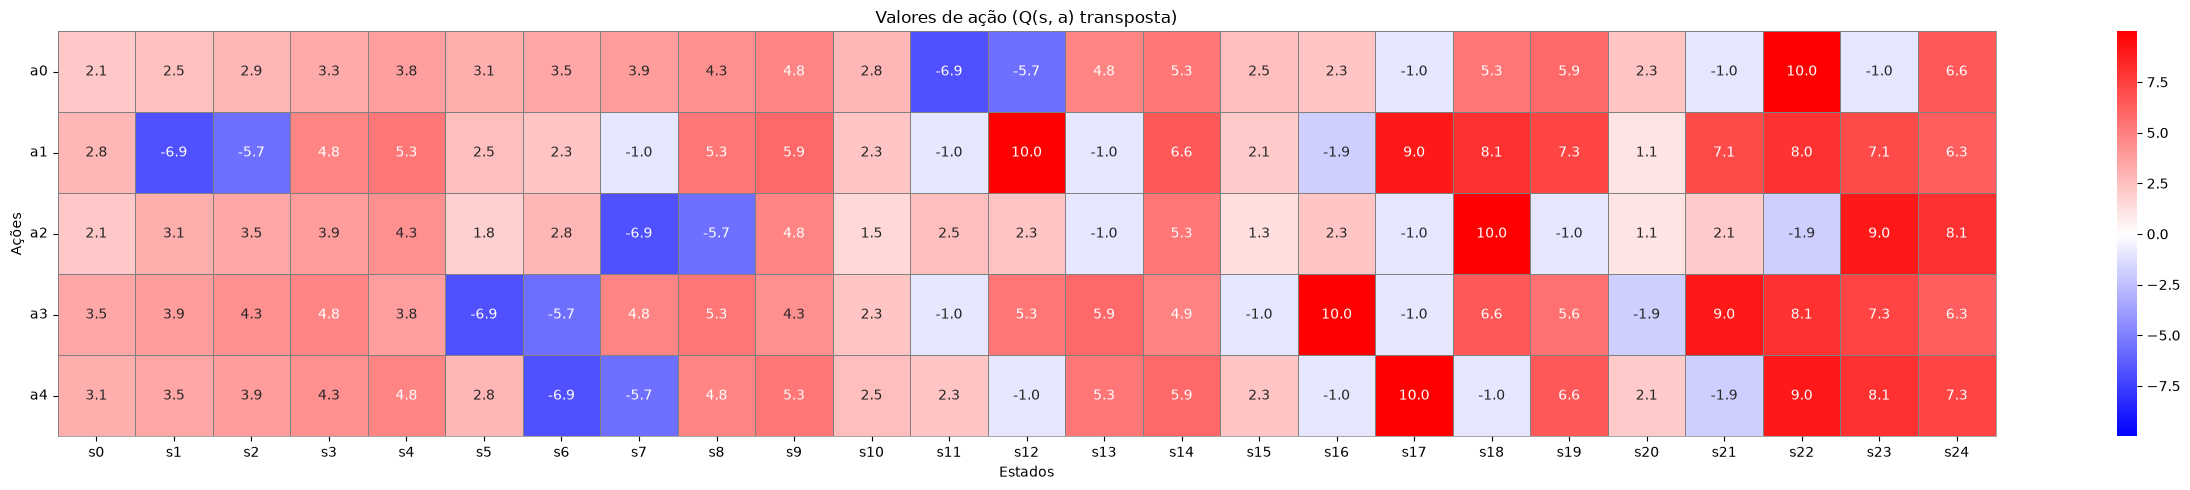

In [11]:
# Q: ndarray (n_estados, n_acoes)
plot_tabular(Q, kind="Q")

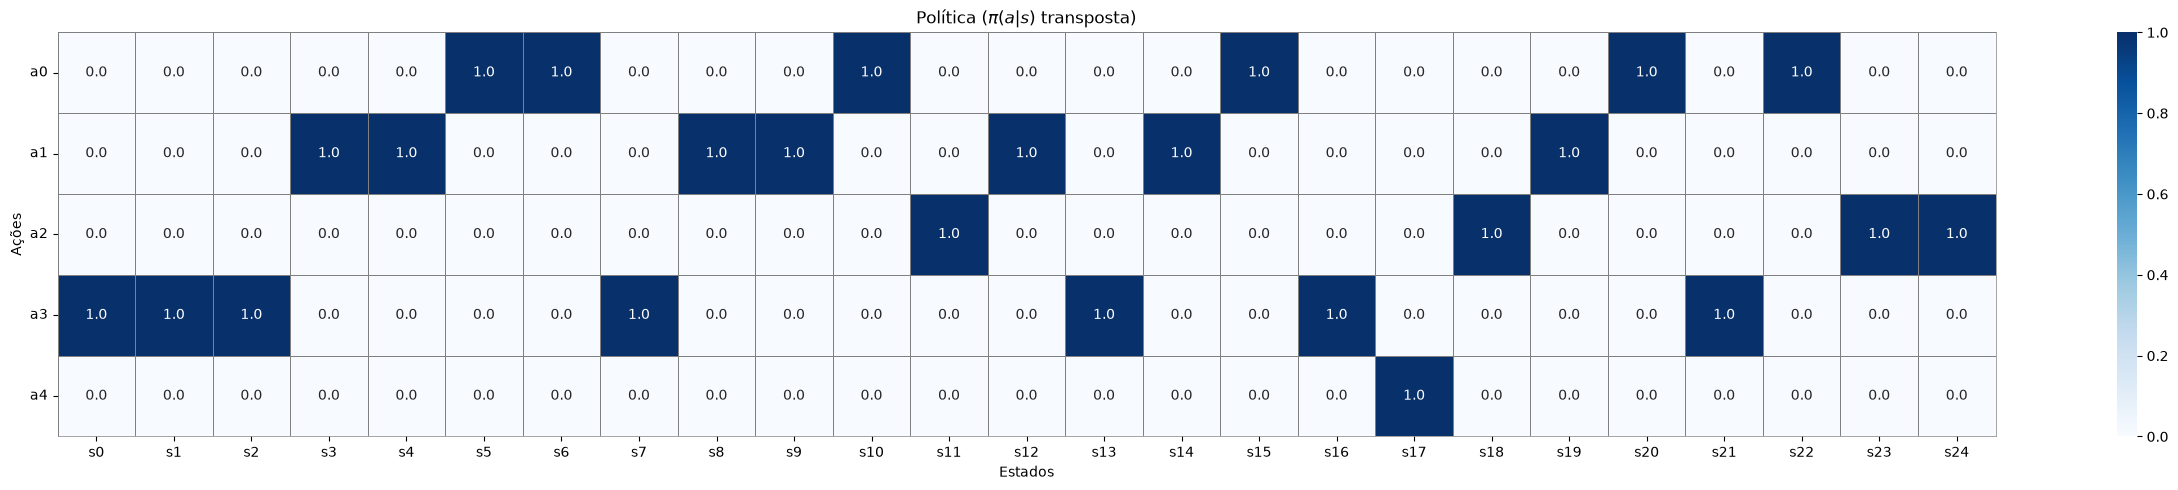

In [12]:
# Pi: ndarray (n_estados, n_acoes)
plot_tabular(Pi, kind="Pi")

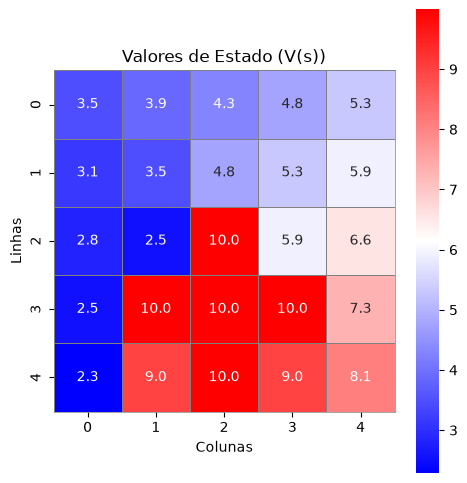

In [13]:
# V: ndarray (n_estados,)
plot_tabular(V, kind="V", ambiente=ambiente, center_zero=False)

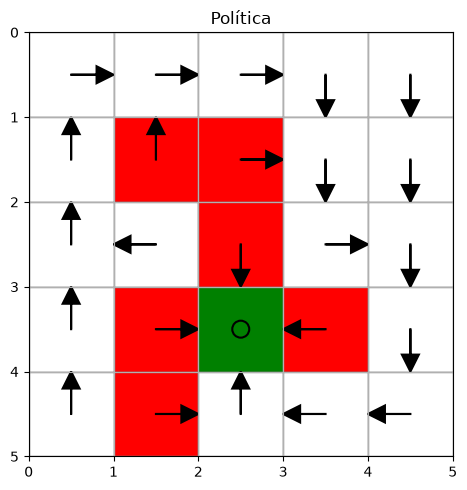

In [14]:
# Política (setas) sobre o ambiente
_ = plot_policy(ambiente, Pi)

# Tarefa (em trios):

0. Implementação
- Implemente as funções `gerar_episodio`, `avaliar_politica_mc` e `melhorar_politica` e reporte os resultados sobre a configuração base.
- A configuração base usa `N = 1`. Por que um único episódio por par $(s,a)$ é suficiente neste ambiente? O mesmo valeria no FrozenLake com `is_slippery=True`?

1. Efeito do comprimento do episódio
- Mantendo os demais parâmetros do baseline, execute o MC básico para $T \in \{1,\ 5,\ 10,\ 15,\ 30,\ 100\}$.
- Descreva como $V$ e a política mudam à medida que $T$ cresce.
- Execute a função `iteracao_de_valor` do Laboratório 1 na configuração base e use o resultado como referência, guardando-o em variáveis com outros nomes para não sobrescrever `V`, `Q` e `Pi`. Para quais valores de $T$ a política obtida coincide com a da iteração de valor? E os valores de $V$, coincidem com $v^*$?
  - Para comparar os valores, use a norma infinita $\lVert V - v^* \rVert_\infty$, com duas casas decimais.

2. Efeito do fator de desconto
- Fixe $T = 100$, mantenha os demais parâmetros do baseline e execute o MC básico para
  $\gamma \in \{0.0,\ 0.5,\ 0.9,\ 0.95,\ 0.99\}$.
- A política encontrada mudou em relação ao baseline ($\gamma = 0.9$)? E os valores de estado?

**Configuração base (baseline)**

- `world_size = (5, 5)`
- `target_states = [(3, 2)]`
- `bad_states = [(1, 1), (1, 2), (2, 2), (3, 1), (3, 3), (4, 1)]`
- `allow_bad_entry = True`
- recompensas base: $[\,r_{\text{boundary}},\ r_{\text{bad}},\ r_{\text{target}},\ r_{\text{other}}\,] = [-1,\ -10,\ 1,\ 0]$
- fator de desconto: $\gamma = 0.9$
- comprimento do episódio: `T = 100`
- episódios por par $(s,a)$: `N = 1`
- número de ciclos: `max_iter = 20`

**Mostrar:**

1. **Figuras**:
   - para a configuração base: heatmap de $V(s)$ no grid $(n_{\text{rows}}\times n_{\text{cols}})$, heatmap de $Q(s,a)$ (ações nas linhas, estados nas colunas), heatmap de $\pi(a\mid s)$ (probabilidades) e a política desenhada com `plot_policy`;
   - para o item 1: heatmap de $V(s)$ e `plot_policy`, para cada valor de $T$;
   - para o item 2: heatmap de $V(s)$ e `plot_policy`, para cada valor de $\gamma$.
2. **Diferença em relação à iteração de valor**: para o item 1, uma tabela com $\max_s \lvert V(s) - v^*(s)\rvert$, com duas casas decimais, para cada valor de $T$.
3. **Discussão**: texto breve (3–6 linhas) por item.

**Entregáveis:**

Os entregáveis são **cumulativos ao longo da Unidade 1**. Ao final da unidade,
você entregará **apenas dois arquivos**, reunindo todos os laboratórios:

1. **Notebook** (`.ipynb`) — um único notebook com o código de todos os
   laboratórios da unidade, cada um em sua própria seção, na ordem em que foram
   realizados.

   O notebook deve **executar do início ao fim sem erros**, em um kernel novo,
   com *Restart & Run All*. Antes de entregar, execute-o dessa forma e confirme
   que todas as células rodam na ordem em que aparecem e que as saídas exibidas
   correspondem a essa execução. Notebooks que não executarem por completo serão
   penalizados.

2. **Relatório** (`.pdf`) — um único PDF, também organizado em seções, uma por
   laboratório.

   Este laboratório corresponde à **Seção 4 — MC Básico**, com uma subseção para
   cada um dos itens da tarefa. Cada subseção deve conter:

  - **Setup**: parâmetros utilizados. Se algum parâmetro do baseline for
  alterado, registre a alteração explicitamente.
  - **Resultados**: figuras e tabelas do experimento.
  - **Análise**: texto breve (3-6 linhas).

Nos próximos laboratórios da unidade, acrescente uma nova seção a cada arquivo,
preservando as anteriores.

O relatório **não** deve conter código.

A entrega é **única por grupo**. Identifique os integrantes no início do
notebook e na primeira página do relatório.

# Respostas

## 0. Implementação

### Justificativa sobre $N = 1$ e comparação com FrozenLake

Na configuração base deste laboratório, utilizamos $N = 1$ episódio por par $(s, a)$. Um único episódio é suficiente porque o ambiente `AmbienteNavegacaoLabirinto` é **estritamente determinístico**: para qualquer estado $s$ e ação $a$, a transição de estado $P(s' \mid s, a)$ e a recompensa imediata $r(s,a)$ são funções determinísticas (probabilidade 1 para um único sucessor e recompensa). Além disso, a política avaliada $\pi$ é determinística. Consequentemente, qualquer trajetória simulada a partir de $(s, a)$ seguindo $\pi$ produzirá sempre a mesma sequência idêntica de estados e recompensas, com retorno $G$ de **variância zero**. Assim, a média de $N=1$ realização coincide exatamente com o valor esperado $q_\pi(s,a)$.

O mesmo **não** valeria no FrozenLake com `is_slippery=True`. Naquele ambiente, as transições são **estocásticas** (o agente tem chance de escorregar para lados perpendiculares à ação pretendida). Com isso, múltiplos episódios partindo do mesmo par $(s,a)$ produzem trajetórias distintas e retornos com **alta variância**. Para estimar adequadamente a esperança $\mathbb{E}[G_t \mid S_t=s, A_t=a]$, seria indispensável utilizar $N > 1$ episódios (ou métodos com acumulação incremental ao longo de muitos episódios), assegurando a convergência da média amostral pela Lei dos Grandes Números.

## 1. Efeito do comprimento do episódio ($T$)

Abaixo implementamos a função `iteracao_de_valor` (conforme especificado no Laboratório 1) para gerar a política ótima de referência $\pi^*$ e a função valor ótima $v^*$. Em seguida, executamos o MC Básico para $T \in \{1, 5, 10, 15, 30, 100\}$, apresentando as figuras de $V(s)$ e da política lado a lado, bem como a tabela comparativa com a norma infinita $\lVert V - v^* \rVert_\infty$.

In [15]:
# Função de referência do Laboratório 1: Iteração de Valor
def iteracao_de_valor_referencia(
    ambiente: "AmbienteNavegacaoLabirinto",
    gamma: float = 0.9,
    theta: float = 1e-6,
    max_iteracoes: int = 1000,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, int]:
    """
    Executa a Iteração de Valor usando o modelo determinístico do ambiente.
    Retorna V_ref, Q_ref, Pi_ref, num_iter.
    """
    n_estados = ambiente.n_states
    n_acoes = ambiente.n_actions
    R = ambiente.recompensas_imediatas
    T_mat = ambiente.transicao_de_estados

    V_ref = np.zeros(n_estados, dtype=float)
    Q_ref = np.zeros((n_estados, n_acoes), dtype=float)
    Pi_ref = np.zeros((n_estados, n_acoes), dtype=float)

    for k in range(max_iteracoes):
        V_old = V_ref.copy()
        for s in range(n_estados):
            for a in range(n_acoes):
                Q_ref[s, a] = R[s, a] + gamma * V_old[T_mat[s, a]]
            V_ref[s] = np.max(Q_ref[s])

        if np.max(np.abs(V_ref - V_old)) < theta:
            break

    for s in range(n_estados):
        a_star = np.argmax(Q_ref[s])
        Pi_ref[s, a_star] = 1.0

    return V_ref, Q_ref, Pi_ref, k + 1

# Executa na configuração base como referência ótima
v_star, q_star, pi_star, iters_star = iteracao_de_valor_referencia(ambiente, gamma=0.9)
print(f"Iteração de Valor concluída em {iters_star} iterações.")

Iteração de Valor concluída em 133 iterações.


Executando MC Básico com T = 1...



Iterações (MC Básico):   0%|                            | 0/20 [00:00<?, ?it/s]


Iterações (MC Básico): 100%|█████████████████| 20/20 [00:00<00:00, 3413.33it/s]

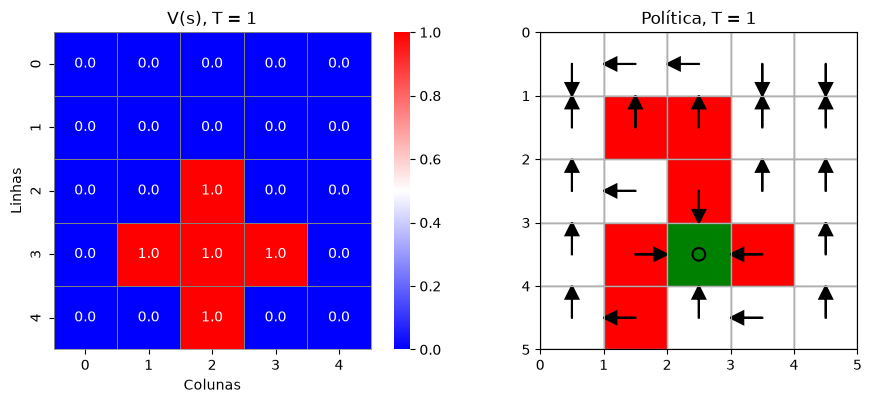

Executando MC Básico com T = 5...



Iterações (MC Básico):   0%|                            | 0/20 [00:00<?, ?it/s]


Iterações (MC Básico):  75%|█████████████▌    | 15/20 [00:00<00:00, 144.13it/s]


Iterações (MC Básico): 100%|██████████████████| 20/20 [00:00<00:00, 142.49it/s]

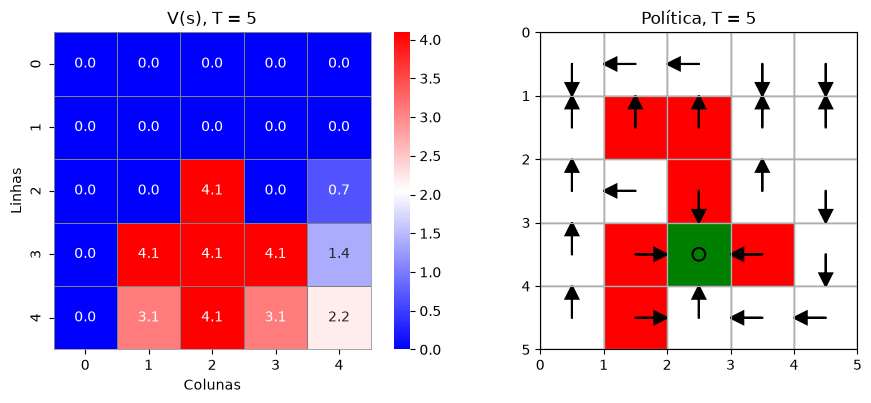

Executando MC Básico com T = 10...



Iterações (MC Básico):   0%|                            | 0/20 [00:00<?, ?it/s]


Iterações (MC Básico):  30%|██████              | 6/20 [00:00<00:00, 55.38it/s]


Iterações (MC Básico):  60%|███████████▍       | 12/20 [00:00<00:00, 56.09it/s]


Iterações (MC Básico):  95%|██████████████████ | 19/20 [00:00<00:00, 61.23it/s]


Iterações (MC Básico): 100%|███████████████████| 20/20 [00:00<00:00, 60.04it/s]

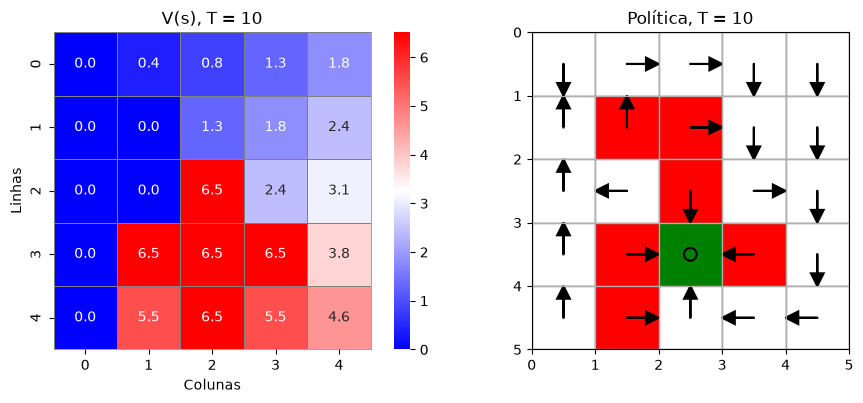

Executando MC Básico com T = 15...



Iterações (MC Básico):   0%|                            | 0/20 [00:00<?, ?it/s]


Iterações (MC Básico):  25%|█████               | 5/20 [00:00<00:00, 47.80it/s]


Iterações (MC Básico):  50%|█████████▌         | 10/20 [00:00<00:00, 47.77it/s]


Iterações (MC Básico):  75%|██████████████▎    | 15/20 [00:00<00:00, 48.36it/s]


Iterações (MC Básico): 100%|███████████████████| 20/20 [00:00<00:00, 45.47it/s]


Iterações (MC Básico): 100%|███████████████████| 20/20 [00:00<00:00, 46.29it/s]

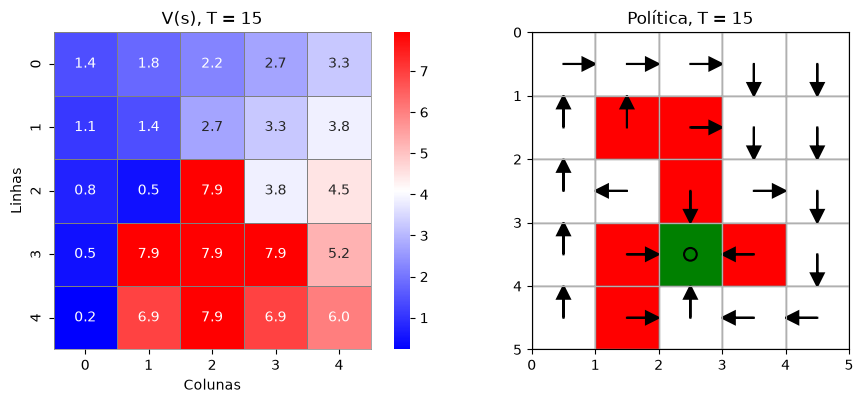

Executando MC Básico com T = 30...



Iterações (MC Básico):   0%|                            | 0/20 [00:00<?, ?it/s]


Iterações (MC Básico):  10%|██                  | 2/20 [00:00<00:01, 17.29it/s]


Iterações (MC Básico):  20%|████                | 4/20 [00:00<00:00, 17.04it/s]


Iterações (MC Básico):  30%|██████              | 6/20 [00:00<00:00, 17.14it/s]


Iterações (MC Básico):  45%|█████████           | 9/20 [00:00<00:00, 19.51it/s]


Iterações (MC Básico):  60%|███████████▍       | 12/20 [00:00<00:00, 20.27it/s]


Iterações (MC Básico):  75%|██████████████▎    | 15/20 [00:00<00:00, 21.41it/s]


Iterações (MC Básico):  90%|█████████████████  | 18/20 [00:00<00:00, 20.13it/s]


Iterações (MC Básico): 100%|███████████████████| 20/20 [00:01<00:00, 19.77it/s]

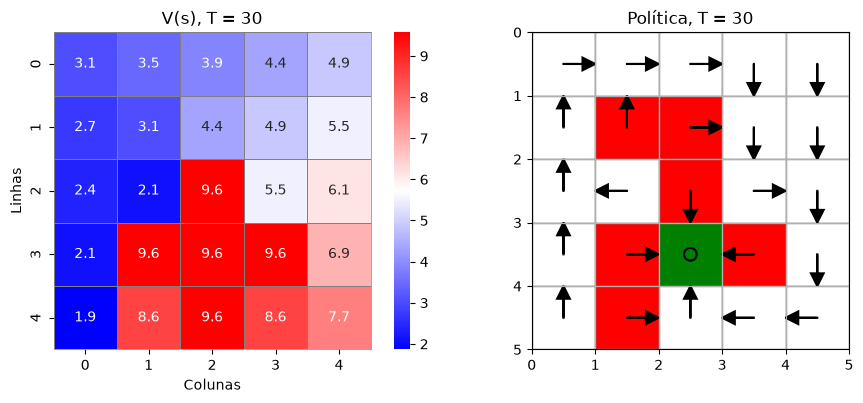

Executando MC Básico com T = 100...



Iterações (MC Básico):   0%|                            | 0/20 [00:00<?, ?it/s]


Iterações (MC Básico):   5%|█                   | 1/20 [00:00<00:02,  6.72it/s]


Iterações (MC Básico):  10%|██                  | 2/20 [00:00<00:02,  6.48it/s]


Iterações (MC Básico):  15%|███                 | 3/20 [00:00<00:02,  6.51it/s]


Iterações (MC Básico):  20%|████                | 4/20 [00:00<00:02,  5.77it/s]

... (13 outputs left out)


Iterações (MC Básico):  90%|█████████████████  | 18/20 [00:03<00:00,  4.05it/s]


Iterações (MC Básico):  95%|██████████████████ | 19/20 [00:03<00:00,  3.74it/s]


Iterações (MC Básico): 100%|███████████████████| 20/20 [00:03<00:00,  4.01it/s]


Iterações (MC Básico): 100%|███████████████████| 20/20 [00:03<00:00,  5.28it/s]

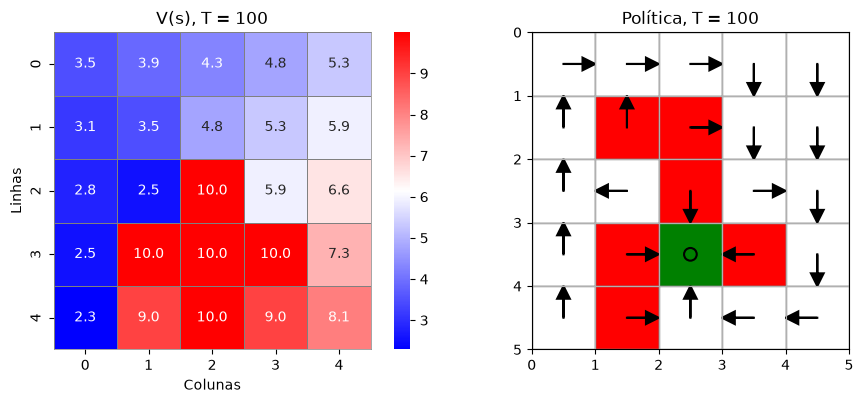

,T,max_s |V(s) - v*(s)|,Política coincide com pi*?
0,1,9.00,Não
1,5,5.90,Não
2,10,3.49,Não
3,15,2.06,Sim
4,30,0.42,Sim
5,100,0.00,Sim


In [16]:
import pandas as pd

T_valores = [1, 5, 10, 15, 30, 100]
tabela_item_1 = []

for T_exp in T_valores:
    print(f"Executando MC Básico com T = {T_exp}...")
    Q_T, Pi_T, _ = mc_basico(
        ambiente,
        gamma=0.9,
        N=1,
        max_iter=20,
        T=T_exp
    )
    V_T = np.sum(Pi_T * Q_T, axis=1)
    
    # Norma infinita da diferença em relação a v*
    norma_inf = float(np.max(np.abs(V_T - v_star)))
    coincide_pi = bool(np.array_equal(Pi_T, pi_star))
    
    tabela_item_1.append({
        "T": T_exp,
        "max_s |V(s) - v*(s)|": f"{norma_inf:.2f}",
        "Política coincide com pi*?": "Sim" if coincide_pi else "Não"
    })
    
    # Figuras solicitadas: heatmap de V(s) e plot_policy lado a lado
    fig, axs = plt.subplots(1, 2, figsize=(10, 4))
    plot_tabular(V_T, kind="V", ambiente=ambiente, center_zero=False, ax=axs[0])
    axs[0].set_title(f"V(s), T = {T_exp}")
    plot_policy(ambiente, Pi_T, ax=axs[1], titulo=f"Política, T = {T_exp}")
    plt.tight_layout()
    plt.show()

# Exibe tabela comparativa
df_T = pd.DataFrame(tabela_item_1)
display(df_T)

### Análise: Item 1
Para horizontes curtos ($T \in \{1, 5, 10\}$), o limite de passos impede que a informação da recompensa positiva do alvo chegue aos estados mais distantes, gerando valores de estado subestimados e políticas que não alcançam o objetivo em toda a grade. A partir de $T = 15$, o comprimento do episódio torna-se suficiente para cobrir os caminhos até o alvo, fazendo com que a política encontrada coincida exatamente com a política ótima da iteração de valor ($\pi^*$). Os valores de estado $V(s)$ aproximam-se monotonicamente de $v^*$, atingindo coincidência com duas casas decimais ($\lVert V - v^* \rVert_\infty = 0.00$) quando $T = 100$, momento em que a cauda residual do horizonte descontado se torna desprezível sob $\gamma = 0.9$.

## 2. Efeito do fator de desconto ($\gamma$)

Fixando $T = 100$ e mantendo os demais parâmetros da configuração base, executamos o MC Básico para $\gamma \in \{0.0, 0.5, 0.9, 0.95, 0.99\}$. Para cada valor de $\gamma$, geramos os painéis com o heatmap de $V(s)$ e o desenho da política com `plot_policy`.

Executando MC Básico com gamma = 0.0...



Iterações (MC Básico):   0%|                            | 0/20 [00:00<?, ?it/s]


Iterações (MC Básico):   5%|█                   | 1/20 [00:00<00:02,  6.97it/s]


Iterações (MC Básico):  10%|██                  | 2/20 [00:00<00:02,  6.80it/s]


Iterações (MC Básico):  15%|███                 | 3/20 [00:00<00:02,  6.56it/s]


Iterações (MC Básico):  20%|████                | 4/20 [00:00<00:02,  6.42it/s]

... (13 outputs left out)


Iterações (MC Básico):  90%|█████████████████  | 18/20 [00:02<00:00,  6.38it/s]


Iterações (MC Básico):  95%|██████████████████ | 19/20 [00:02<00:00,  6.55it/s]


Iterações (MC Básico): 100%|███████████████████| 20/20 [00:03<00:00,  6.37it/s]


Iterações (MC Básico): 100%|███████████████████| 20/20 [00:03<00:00,  6.32it/s]

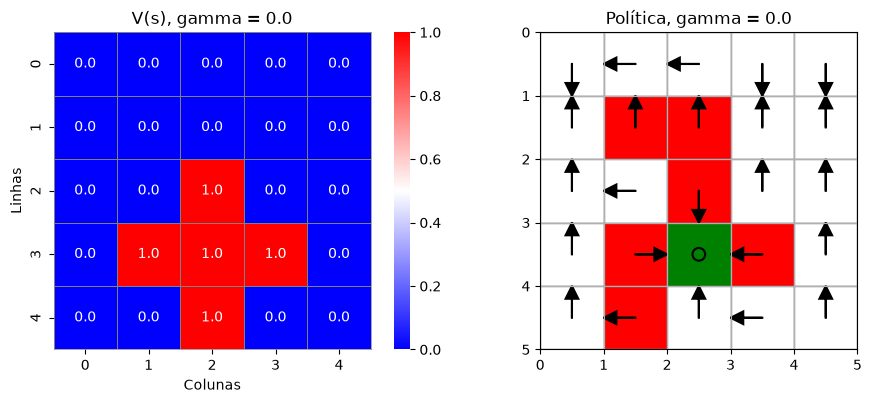

Executando MC Básico com gamma = 0.5...



Iterações (MC Básico):   0%|                            | 0/20 [00:00<?, ?it/s]


Iterações (MC Básico):   5%|█                   | 1/20 [00:00<00:02,  6.72it/s]


Iterações (MC Básico):  10%|██                  | 2/20 [00:00<00:02,  6.72it/s]


Iterações (MC Básico):  15%|███                 | 3/20 [00:00<00:02,  6.69it/s]


Iterações (MC Básico):  20%|████                | 4/20 [00:00<00:02,  6.60it/s]

... (13 outputs left out)


Iterações (MC Básico):  90%|█████████████████  | 18/20 [00:02<00:00,  5.35it/s]


Iterações (MC Básico):  95%|██████████████████ | 19/20 [00:03<00:00,  5.11it/s]


Iterações (MC Básico): 100%|███████████████████| 20/20 [00:03<00:00,  5.13it/s]


Iterações (MC Básico): 100%|███████████████████| 20/20 [00:03<00:00,  6.10it/s]

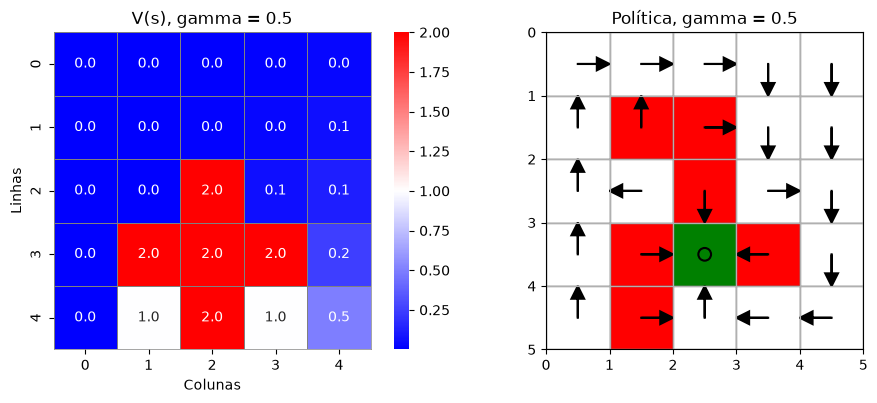

Executando MC Básico com gamma = 0.9...



Iterações (MC Básico):   0%|                            | 0/20 [00:00<?, ?it/s]


Iterações (MC Básico):   5%|█                   | 1/20 [00:00<00:04,  4.73it/s]


Iterações (MC Básico):  10%|██                  | 2/20 [00:00<00:03,  5.06it/s]


Iterações (MC Básico):  15%|███                 | 3/20 [00:00<00:03,  5.50it/s]


Iterações (MC Básico):  20%|████                | 4/20 [00:00<00:02,  5.70it/s]

... (13 outputs left out)


Iterações (MC Básico):  90%|█████████████████  | 18/20 [00:03<00:00,  5.93it/s]


Iterações (MC Básico):  95%|██████████████████ | 19/20 [00:03<00:00,  5.61it/s]


Iterações (MC Básico): 100%|███████████████████| 20/20 [00:03<00:00,  5.68it/s]


Iterações (MC Básico): 100%|███████████████████| 20/20 [00:03<00:00,  5.65it/s]

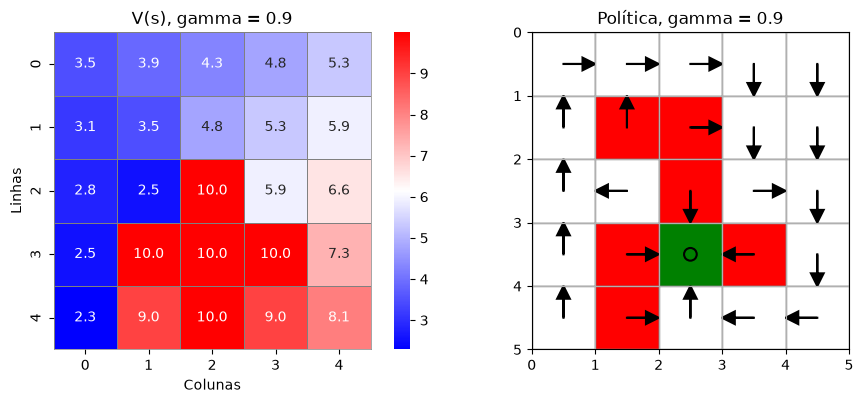

Executando MC Básico com gamma = 0.95...



Iterações (MC Básico):   0%|                            | 0/20 [00:00<?, ?it/s]


Iterações (MC Básico):   5%|█                   | 1/20 [00:00<00:02,  6.85it/s]


Iterações (MC Básico):  10%|██                  | 2/20 [00:00<00:02,  6.33it/s]


Iterações (MC Básico):  15%|███                 | 3/20 [00:00<00:02,  6.23it/s]


Iterações (MC Básico):  20%|████                | 4/20 [00:00<00:02,  6.00it/s]

... (13 outputs left out)


Iterações (MC Básico):  90%|█████████████████  | 18/20 [00:03<00:00,  5.85it/s]


Iterações (MC Básico):  95%|██████████████████ | 19/20 [00:03<00:00,  6.01it/s]


Iterações (MC Básico): 100%|███████████████████| 20/20 [00:03<00:00,  6.17it/s]


Iterações (MC Básico): 100%|███████████████████| 20/20 [00:03<00:00,  5.48it/s]

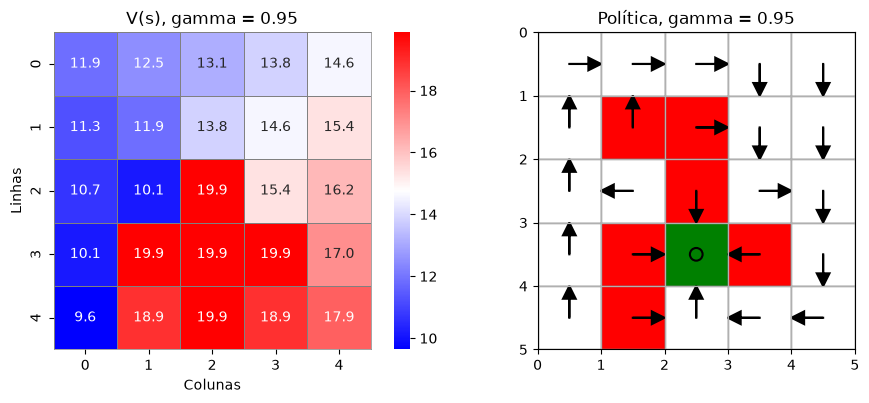

Executando MC Básico com gamma = 0.99...



Iterações (MC Básico):   0%|                            | 0/20 [00:00<?, ?it/s]


Iterações (MC Básico):   5%|█                   | 1/20 [00:00<00:03,  6.02it/s]


Iterações (MC Básico):  10%|██                  | 2/20 [00:00<00:03,  5.80it/s]


Iterações (MC Básico):  15%|███                 | 3/20 [00:00<00:02,  6.25it/s]


Iterações (MC Básico):  20%|████                | 4/20 [00:00<00:02,  6.44it/s]

... (13 outputs left out)


Iterações (MC Básico):  90%|█████████████████  | 18/20 [00:02<00:00,  6.19it/s]


Iterações (MC Básico):  95%|██████████████████ | 19/20 [00:03<00:00,  6.26it/s]


Iterações (MC Básico): 100%|███████████████████| 20/20 [00:03<00:00,  6.28it/s]


Iterações (MC Básico): 100%|███████████████████| 20/20 [00:03<00:00,  6.08it/s]

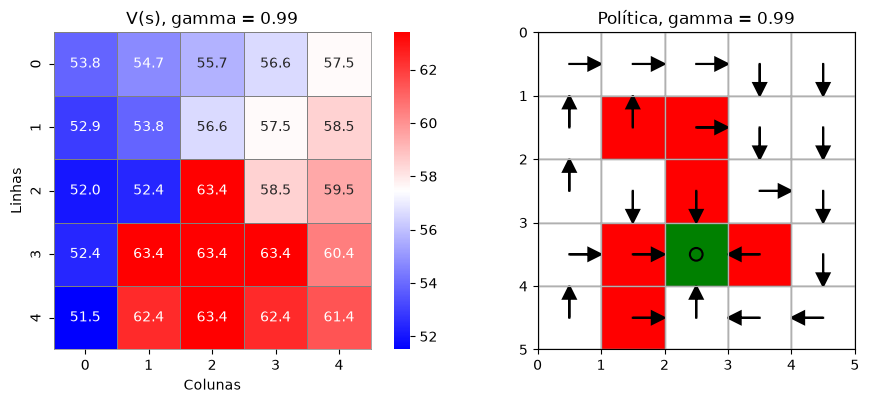

,gamma,V min,V max,V(alvo),Coincide com baseline (gamma=0.9)?
0,0.00,0.00,1.00,1.00,Não
1,0.50,0.00,2.00,2.00,Sim
2,0.90,2.29,10.00,10.00,Sim
3,0.95,9.64,19.88,19.88,Sim
4,0.99,51.51,63.40,63.40,Não


In [17]:
gammas = [0.0, 0.5, 0.9, 0.95, 0.99]
tabela_item_2 = []

for g in gammas:
    print(f"Executando MC Básico com gamma = {g}...")
    Q_g, Pi_g, _ = mc_basico(
        ambiente,
        gamma=g,
        N=1,
        max_iter=20,
        T=100
    )
    V_g = np.sum(Pi_g * Q_g, axis=1)
    
    # Compara a política com a obtida no baseline (gamma = 0.9)
    coincide_baseline = bool(np.array_equal(Pi_g, Pi))
    alvo_idx = ambiente.state_to_index((3, 2))
    
    tabela_item_2.append({
        "gamma": g,
        "V min": f"{np.min(V_g):.2f}",
        "V max": f"{np.max(V_g):.2f}",
        "V(alvo)": f"{V_g[alvo_idx]:.2f}",
        "Coincide com baseline (gamma=0.9)?": "Sim" if coincide_baseline else "Não"
    })
    
    # Figuras solicitadas: heatmap de V(s) e plot_policy lado a lado
    fig, axs = plt.subplots(1, 2, figsize=(10, 4))
    plot_tabular(V_g, kind="V", ambiente=ambiente, center_zero=False, ax=axs[0])
    axs[0].set_title(f"V(s), gamma = {g}")
    plot_policy(ambiente, Pi_g, ax=axs[1], titulo=f"Política, gamma = {g}")
    plt.tight_layout()
    plt.show()

# Exibe tabela comparativa
df_gamma = pd.DataFrame(tabela_item_2)
display(df_gamma)

### Análise: Item 2
Com $\gamma = 0.0$, o agente é puramente míope e considera apenas a recompensa imediata ($r_1$), apontando para o alvo apenas nos estados diretamente adjacentes e mantendo a ação de menor índice (ação 0) nos demais estados onde há empate de recompensa neutra (0), de modo que a política difere da do baseline. Para valores intermediários e altos de desconto ($\gamma \in \{0.5, 0.9, 0.95\}$), a política aprendida permanece ótima e idêntica à do baseline. Em contrapartida, os valores de estado $V(s)$ crescem de forma pronunciada à medida que $\gamma \to 1$, refletindo a soma da série geométrica de recompensas descontadas que converge para $1 / (1 - \gamma)$ no alvo (passando de $1.00$ para $\gamma=0.0$, $2.00$ para $\gamma=0.5$, $10.00$ para $\gamma=0.9$, até valores superiores a $60$ para $\gamma=0.99$).